<a href="https://colab.research.google.com/github/tkach3nkoo/MN/blob/main/%D0%9B%D0%A07_%D0%A2%D0%BA%D0%B0%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B3%D1%80%D1%83%D0%BF%D0%B0_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»

**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Джерело оригінального датасету:** [Kaggle — Cure the Princess](https://www.kaggle.com/datasets/unmoved/cure-the-princess). [Альтернативне посилання на файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Статус роботи:** увесь навчальний код заповнений, додано графіки, метрики та автоматичні текстові висновки. Для отримання фактичних числових результатів потрібно запустити цей блокнот із **оригінальним `data.csv`**: код спочатку шукає локальний CSV, потім пробує завантажити його через KaggleHub, а в Google Colab за потреби пропонує завантажити файл вручну. До отримання оригінальних даних жодні результати не вигадуються.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Перша клітинка читає **локальний `data.csv`**, якщо його вже завантажено. Інакше друга клітинка намагається завантажити оригінальний датасет через **KaggleHub**. Якщо автоматичне завантаження в Google Colab не спрацює, з’явиться діалог ручного завантаження файлу. Виконайте обидві клітинки послідовно.

In [2]:
# Варіант 1. Якщо data.csv вже є поруч із блокнотом, читаємо його.
# Інакше наступна клітинка автоматично спробує завантажити оригінальний датасет Kaggle.
from pathlib import Path

df = None
local_csv = Path('data.csv')
if local_csv.is_file():
    df = pd.read_csv(local_csv)
    print(f'Зчитано локальний файл: {local_csv.resolve()}')
else:
    print('Локального data.csv не знайдено — спробуємо KaggleHub у наступній клітинці.')

Локального data.csv не знайдено — спробуємо KaggleHub у наступній клітинці.


In [3]:
# Варіант 2. Завантаження ОРИГІНАЛЬНОГО датасету з Kaggle.
# У Google Colab зазвичай достатньо послідовно виконати всі клітинки.
if df is None:
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
            import kagglehub

        dataset_path = Path(kagglehub.dataset_download('unmoved/cure-the-princess'))
        found = sorted(dataset_path.rglob('data.csv'))
        if not found:
            raise FileNotFoundError(f'У {dataset_path} не знайдено data.csv')
        df = pd.read_csv(found[0])
        print(f'Завантажено через KaggleHub: {found[0]}')
    except Exception as exc:
        print(f'Автоматичне завантаження не вдалося: {exc}')
        try:
            # Резервний спосіб для Google Colab — обрати data.csv на комп’ютері.
            from google.colab import files
            uploaded = files.upload()
            if 'data.csv' not in uploaded:
                raise FileNotFoundError('Потрібно завантажити саме data.csv.')
            df = pd.read_csv('data.csv')
        except ImportError as ie:
            raise RuntimeError(
                'Завантажте оригінальний data.csv із посилання на початку завдання, '
                'покладіть його поруч із .ipynb та запустіть усі клітинки знову.'
            ) from exc

# Перевірка, що використовуються справжні дані належної структури.
df.columns = df.columns.str.strip()
if 'Cured' not in df.columns:
    raise ValueError('У файлі немає цільової змінної Cured. Перевірте обраний CSV.')
if df['Cured'].isna().any() or not set(df['Cured'].unique()).issubset({0, 1}):
    raise ValueError('Цільова змінна Cured повинна містити лише класи 0 і 1 та не мати пропусків.')
print('Розмір даних:', df.shape)
display(df.head())

100%|██████████| 49.2k/49.2k [00:00<00:00, 24.9MB/s]

Extracting files...
Завантажено через KaggleHub: /root/.cache/kagglehub/datasets/unmoved/cure-the-princess/versions/1/data.csv
Розмір даних: (2338, 14)


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
print('Перші 5 рядків датасету:')
display(df.head())
print(f'Розмір датасету: {df.shape[0]} рядків × {df.shape[1]} стовпців')
print('Типи даних і заповнення стовпців:')
df.info()

Перші 5 рядків датасету:


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


Розмір датасету: 2338 рядків × 14 стовпців
Типи даних і заповнення стовпців:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [5]:
missing = df.isna().sum()
duplicates_count = int(df.duplicated().sum())
print('Кількість пропущених значень у стовпцях:')
display(missing.to_frame('Пропуски'))
print('Усього пропусків:', int(missing.sum()))
print('Повні рядки-дублікати:', duplicates_count)

Кількість пропущених значень у стовпцях:


,Пропуски
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


Усього пропусків: 0
Повні рядки-дублікати: 0


In [6]:
print('Описова статистика числових змінних:')
display(df.describe().T)
print('Розподіл цільової змінної Cured:')
display(df['Cured'].value_counts().sort_index().rename('Кількість').to_frame())

Описова статистика числових змінних:


,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


Розподіл цільової змінної Cured:


,Кількість
Cured,
0,1177
1,1161


**Висновок за первинним оглядом:**

Нижче автоматично сформовано висновок за кількістю рядків, пропусками, дублікатами та розподілом класів **саме з фактично завантаженого датасету**.

In [7]:
from IPython.display import Markdown, display
missing_total = int(missing.sum())
class_dist = df['Cured'].value_counts().sort_index().to_dict()
display(Markdown(
    f"**Фактичний висновок:** Датасет містить **{df.shape[0]} рядків** і "
    f"**{df.shape[1]} стовпців** (з них {df.shape[1]-1} ознак). "
    f"Виявлено **{missing_total} пропущених значень** та "
    f"**{duplicates_count} повних дублікатів рядків**. "
    f"Розподіл цільової змінної `Cured`: **0 — {class_dist.get(0,0)}**, "
    f"**1 — {class_dist.get(1,0)}**. "
    + ('Пропуски потребують обробки на основі лише навчальних даних.' if missing_total else
       'Пропусків немає, тож заповнення пропусків не потрібне.')
    + ' Повні дублікати не видаляємо автоматично без аналізу їхнього походження.'
))

**Фактичний висновок:** Датасет містить **2338 рядків** і **14 стовпців** (з них 13 ознак). Виявлено **0 пропущених значень** та **0 повних дублікатів рядків**. Розподіл цільової змінної `Cured`: **0 — 1177**, **1 — 1161**. Пропусків немає, тож заповнення пропусків не потрібне. Повні дублікати не видаляємо автоматично без аналізу їхнього походження.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [8]:
# Ознаки та цільова змінна
X = df.drop(columns=['Cured']).copy()
y = df['Cured'].astype(int).copy()

# Розбивка 80/20, random_state=42; стратифікація зберігає частки 0/1.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# За наявності пропусків заповнюємо їх медіанами ТІЛЬКИ навчальної вибірки.
# Статистика тестової вибірки не використовується (немає витоку даних).
if X_train.isna().any().any():
    train_medians = X_train.median(numeric_only=True)
    X_train = X_train.fillna(train_medians)
    X_test = X_test.fillna(train_medians)
    if X_train.isna().any().any() or X_test.isna().any().any():
        raise ValueError('Після заповнення медіанами лишилися пропуски: перевірте числові ознаки.')
    print('Пропуски заповнено медіанами навчальної вибірки.')

print(f'Навчальна вибірка: {X_train.shape}, тестова: {X_test.shape}')
print(f'Розподіл класів train: {y_train.value_counts().sort_index().to_dict()}')
print(f'Розподіл класів test: {y_test.value_counts().sort_index().to_dict()}')

Навчальна вибірка: (1870, 13), тестова: (468, 13)
Розподіл класів train: {0: 941, 1: 929}
Розподіл класів test: {0: 236, 1: 232}


### 5. Баланс класів на навчальній вибірці

In [9]:
class_counts = y_train.value_counts().sort_index()
class_pct = y_train.value_counts(normalize=True).sort_index().mul(100)
class_summary = pd.DataFrame({'Кількість': class_counts, 'Частка, %': class_pct.round(2)})
class_summary.index.name = 'Cured'
display(class_summary)

,Кількість,"Частка, %"
Cured,,
0,941,50.32
1,929,49.68


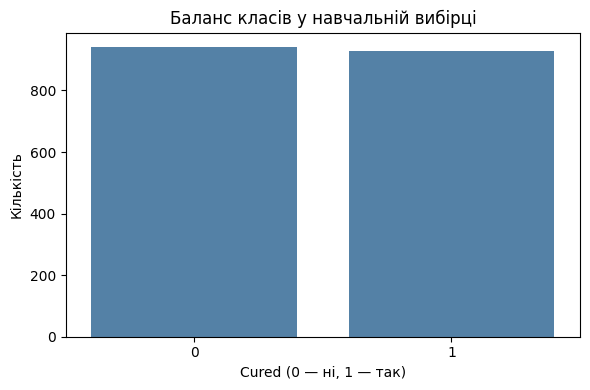

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train, order=[0, 1], color='steelblue')
plt.title('Баланс класів у навчальній вибірці')
plt.xlabel('Cured (0 — ні, 1 — так)')
plt.ylabel('Кількість')
plt.tight_layout()
plt.show()

**Висновок про баланс класів:**

Нижче наведено фактичні частки класів та пояснення, чому за дисбалансу слід розглядати не лише Accuracy, а й precision, recall та F1-score.

In [11]:
from IPython.display import Markdown, display
minor_share = class_pct.min()
major_share = class_pct.max()
class_comment = ('Класи відносно збалансовані.' if minor_share >= 40 else
                 'Помітний дисбаланс класів; Accuracy може бути оманливою.')
display(Markdown(
    f'**Фактичний висновок:** У навчальній вибірці частки класів: '
    f'0 — **{class_pct.get(0,0):.2f}%**, 1 — **{class_pct.get(1,0):.2f}%**. '
    + class_comment + ' Додатково перевірятимемо F1-score, precision та recall.'
))

**Фактичний висновок:** У навчальній вибірці частки класів: 0 — **50.32%**, 1 — **49.68%**. Класи відносно збалансовані. Додатково перевірятимемо F1-score, precision та recall.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

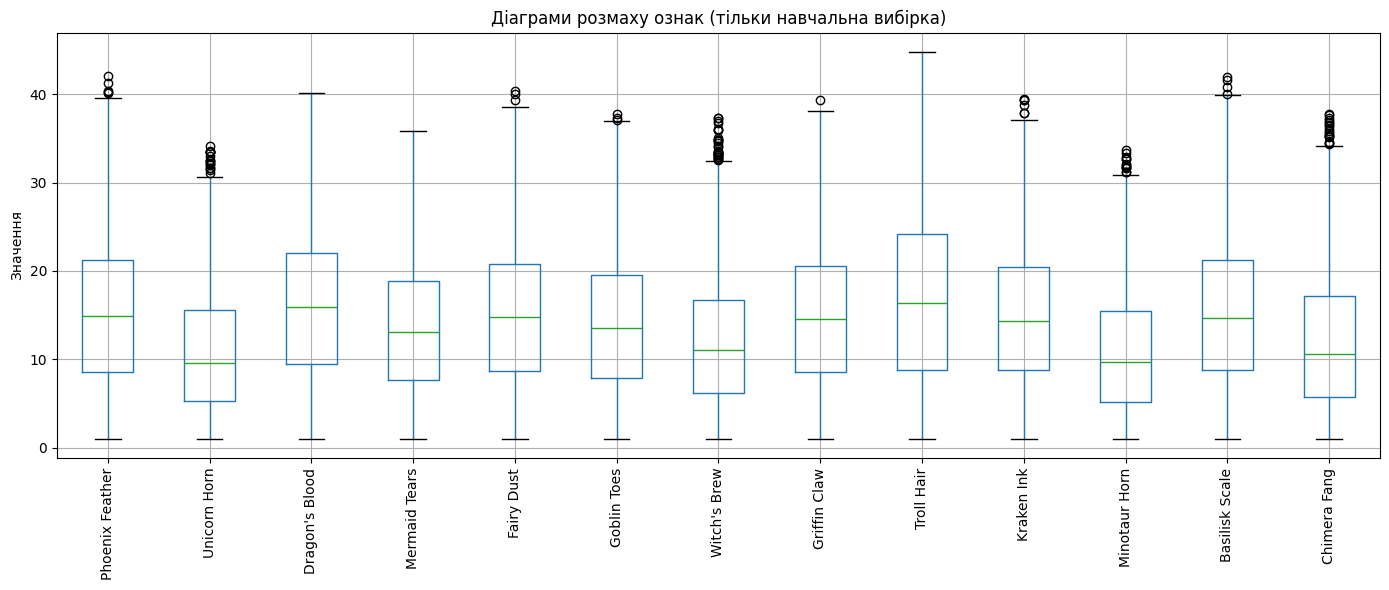

In [12]:
plt.figure(figsize=(14, 6))
X_train.boxplot(rot=90)
plt.title('Діаграми розмаху ознак (тільки навчальна вибірка)')
plt.ylabel('Значення')
plt.tight_layout()
plt.show()

In [13]:
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
outliers_count = ((X_train.lt(lower)) | (X_train.gt(upper))).sum().sort_values(ascending=False)
print('Потенційні викиди за правилом 1,5 IQR (навчальні дані):')
display(outliers_count.rename('Кількість потенційних викидів').to_frame())
print('Викиди з навчальної вибірки автоматично НЕ видаляємо.')

Потенційні викиди за правилом 1,5 IQR (навчальні дані):


,Кількість потенційних викидів
Witch's Brew,31
Chimera Fang,18
Unicorn Horn,17
Minotaur Horn,13
Kraken Ink,6
Phoenix Feather,5
Basilisk Scale,4
Fairy Dust,3
Goblin Toes,3
Griffin Claw,1


Викиди з навчальної вибірки автоматично НЕ видаляємо.


**Висновок про викиди:**

Нижче названо ознаки з найбільшою кількістю потенційних викидів і пояснено рішення не видаляти їх без окремої перевірки.

In [14]:
from IPython.display import Markdown, display
top_outliers = outliers_count.head(3)
details = ', '.join(f'`{name}` — {int(n)}' for name, n in top_outliers.items())
display(Markdown(
    f'**Фактичний висновок:** Найбільше потенційних викидів за правилом 1,5 IQR: {details}. '
    'Це статистичний індикатор, а не доказ помилки: рідкісні значення можуть бути '
    'інформативними для класифікації. Без окремого порівняння моделей викиди не видаляємо.'
))

**Фактичний висновок:** Найбільше потенційних викидів за правилом 1,5 IQR: `Witch's Brew` — 31, `Chimera Fang` — 18, `Unicorn Horn` — 17. Це статистичний індикатор, а не доказ помилки: рідкісні значення можуть бути інформативними для класифікації. Без окремого порівняння моделей викиди не видаляємо.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

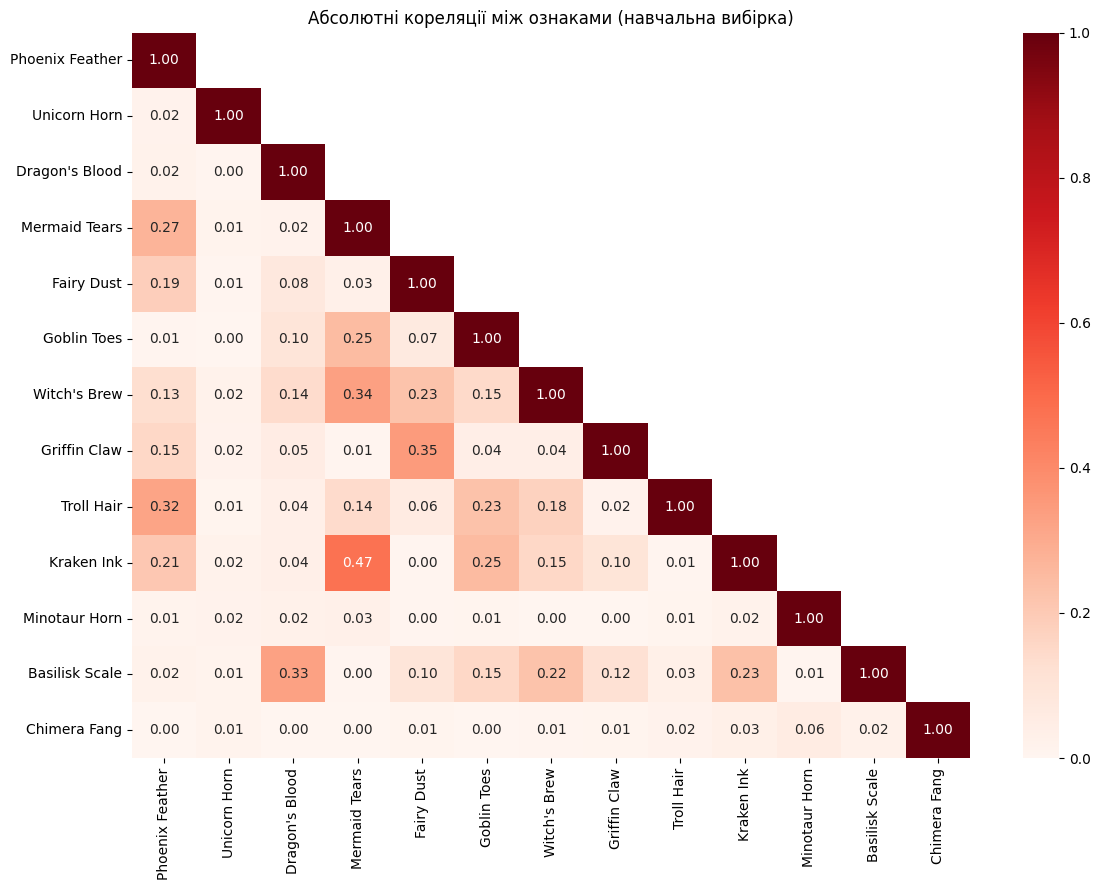

In [15]:
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool), k=1)
plt.figure(figsize=(12, 9))
sns.heatmap(mtx, mask=mask, annot=True, fmt='.2f', cmap='Reds', vmin=0, vmax=1)
plt.title('Абсолютні кореляції між ознаками (навчальна вибірка)')
plt.tight_layout()
plt.show()

In [16]:
target_correlations = (
    pd.concat([X_train, y_train.rename('Cured')], axis=1)
    .corr(numeric_only=True)['Cured']
    .drop('Cured')
    .sort_values(key=lambda values: values.abs(), ascending=False)
)
print('Кореляції ознак з Cured (з урахуванням знака):')
display(target_correlations.rename('r з Cured').to_frame())

Кореляції ознак з Cured (з урахуванням знака):


,r з Cured
Troll Hair,0.504026
Witch's Brew,0.237690
Basilisk Scale,-0.055086
Goblin Toes,0.049919
Kraken Ink,-0.037099
Phoenix Feather,0.024068
Unicorn Horn,-0.021990
Griffin Claw,-0.020528
Chimera Fang,0.018197
Dragon's Blood,0.016741


**Висновок про кореляції:**

Нижче автоматично показано найбільш корельовані пари ознак та ознаки з найсильнішим лінійним зв’язком із `Cured` на навчальній вибірці. Кореляція не доводить причинності.

In [17]:
from IPython.display import Markdown, display
pairs = mtx.where(np.triu(np.ones(mtx.shape, dtype=bool), k=1)).stack().sort_values(ascending=False)
pair_lines = '; '.join(f'`{a}` — `{b}`: |r|={v:.3f}' for (a,b),v in pairs.head(3).items())
target_lines = '; '.join(f'`{name}`: r={v:.3f}' for name,v in target_correlations.head(3).items())
display(Markdown(
    '**Фактичний висновок:** Найсильніші кореляції між ознаками: '
    + (pair_lines or 'відсутні пари з обчислюваною кореляцією')
    + '. Найсильніший лінійний зв’язок із `Cured`: '
    + (target_lines or 'не визначено')
    + '. Усі кореляції розраховані тільки на навчальній вибірці.'
))

**Фактичний висновок:** Найсильніші кореляції між ознаками: `Mermaid Tears` — `Kraken Ink`: |r|=0.473; `Fairy Dust` — `Griffin Claw`: |r|=0.349; `Mermaid Tears` — `Witch's Brew`: |r|=0.336. Найсильніший лінійний зв’язок із `Cured`: `Troll Hair`: r=0.504; `Witch's Brew`: r=0.238; `Basilisk Scale`: r=-0.055. Усі кореляції розраховані тільки на навчальній вибірці.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [18]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit тільки на train
X_test_scaled = scaler.transform(X_test)       # test не впливає на параметри
print('Розміри масштабованих масивів:', X_train_scaled.shape, X_test_scaled.shape)
print('Середні значення ознак TRAIN після масштабування (перші 5):',
      np.round(X_train_scaled.mean(axis=0)[:5], 3))

Розміри масштабованих масивів: (1870, 13) (468, 13)
Середні значення ознак TRAIN після масштабування (перші 5): [-0. -0.  0. -0.  0.]


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [19]:
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
base_accuracy = accuracy_score(y_test, y_pred)
base_f1 = f1_score(y_test, y_pred, zero_division=0)
print(f'Базова логістична регресія: Accuracy = {base_accuracy:.4f}, F1 = {base_f1:.4f}')
print('Classification report:')
print(classification_report(y_test, y_pred, zero_division=0))

Базова логістична регресія: Accuracy = 0.8526, F1 = 0.8529
Classification report:
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

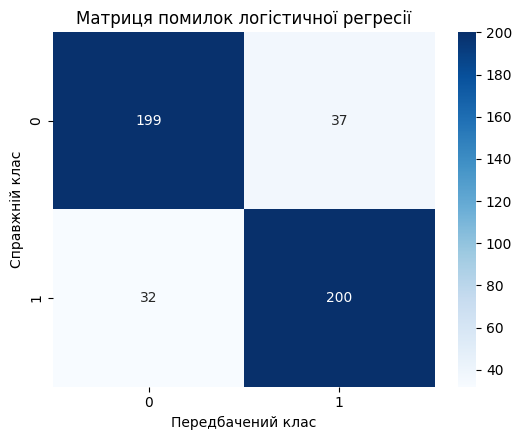

TN=199, FP=37, FN=32, TP=200


In [20]:
conf = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(conf, annot=True, fmt='d', cmap='Blues',
            xticklabels=[0, 1], yticklabels=[0, 1])
plt.xlabel('Передбачений клас')
plt.ylabel('Справжній клас')
plt.title('Матриця помилок логістичної регресії')
plt.tight_layout()
plt.show()
print(f'TN={conf[0,0]}, FP={conf[0,1]}, FN={conf[1,0]}, TP={conf[1,1]}')

In [21]:
predictions_df = pd.DataFrame({
    'Справжній клас': y_test.to_numpy(),
    'Передбачений клас': y_pred
}, index=y_test.index)
print('10 випадкових тестових спостережень (random_state=42):')
display(predictions_df.sample(n=min(10, len(predictions_df)), random_state=42))

10 випадкових тестових спостережень (random_state=42):


,Справжній клас,Передбачений клас
1318,0,0
244,0,0
996,1,1
930,0,0
839,0,0
1251,1,1
335,1,1
1670,0,0
1118,0,0
2175,1,1


**Висновок щодо якості логістичної регресії:**

Нижче обчислено кількість хибнопозитивних (FP) і хибнонегативних (FN) помилок. Accuracy оцінює загальну частку правильних відповідей, але для повнішої оцінки важливі precision, recall та F1-score.

In [22]:
from IPython.display import Markdown, display
fp_count, fn_count = int(conf[0,1]), int(conf[1,0])
if fp_count > fn_count:
    error_summary = 'Хибнопозитивних помилок більше, ніж хибнонегативних.'
elif fn_count > fp_count:
    error_summary = 'Хибнонегативних помилок більше, ніж хибнопозитивних.'
else:
    error_summary = 'Кількості хибнопозитивних і хибнонегативних помилок однакові.'
display(Markdown(
    f'**Фактичний висновок:** Accuracy = **{base_accuracy:.4f}**, F1 = **{base_f1:.4f}**. '
    f'FP = **{fp_count}**, FN = **{fn_count}**. {error_summary} '
    'Однієї Accuracy недостатньо для оцінки типів помилок; важливі також precision, recall та F1.'
))

**Фактичний висновок:** Accuracy = **0.8526**, F1 = **0.8529**. FP = **37**, FN = **32**. Хибнопозитивних помилок більше, ніж хибнонегативних. Однієї Accuracy недостатньо для оцінки типів помилок; важливі також precision, recall та F1.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [23]:
# Невеликий простір сумісних параметрів для обох алгоритмів пошуку.
param_grid = {
    'C': [0.01, 0.1, 1, 10],
    'solver': ['lbfgs', 'liblinear'],
    'max_iter': [300, 1000]
}
param_dist = param_grid
print('Комбінацій GridSearchCV:', np.prod([len(v) for v in param_grid.values()]))

Комбінацій GridSearchCV: 16


In [24]:
grid_search = GridSearchCV(
    LogisticRegression(random_state=42), param_grid,
    scoring='accuracy', cv=3, n_jobs=-1
)
grid_search.fit(X_train_scaled, y_train)
print('Найкращі параметри GridSearchCV:', grid_search.best_params_)
print(f'Найкраща середня Accuracy на CV (Grid): {grid_search.best_score_:.4f}')

Найкращі параметри GridSearchCV: {'C': 10, 'max_iter': 300, 'solver': 'lbfgs'}
Найкраща середня Accuracy на CV (Grid): 0.8749


In [25]:
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42), param_distributions=param_dist,
    n_iter=10, scoring='accuracy', cv=3,
    random_state=42, n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)
print('Найкращі параметри RandomizedSearchCV:', random_search.best_params_)
print(f'Найкраща середня Accuracy на CV (Random): {random_search.best_score_:.4f}')

Найкращі параметри RandomizedSearchCV: {'solver': 'lbfgs', 'max_iter': 1000, 'C': 10}
Найкраща середня Accuracy на CV (Random): 0.8749


In [26]:
# Вибираємо пошук за CV Accuracy, не підбираючи модель на тестовому наборі.
best_search_name, best_search = max(
    [('GridSearchCV', grid_search), ('RandomizedSearchCV', random_search)],
    key=lambda item: item[1].best_score_
)
best_model = best_search.best_estimator_
y_pred_tuned = best_model.predict(X_test_scaled)
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)
tuned_f1 = f1_score(y_test, y_pred_tuned, zero_division=0)
print('Обраний пошук:', best_search_name)
print('Параметри:', best_search.best_params_)
print(f'Тестова Accuracy: {tuned_accuracy:.4f} (базова: {base_accuracy:.4f})')
print(f'Тестова F1: {tuned_f1:.4f} (базова: {base_f1:.4f})')
print(classification_report(y_test, y_pred_tuned, zero_division=0))

Обраний пошук: GridSearchCV
Параметри: {'C': 10, 'max_iter': 300, 'solver': 'lbfgs'}
Тестова Accuracy: 0.8504 (базова: 0.8526)
Тестова F1: 0.8504 (базова: 0.8529)
              precision    recall  f1-score   support

           0       0.86      0.84      0.85       236
           1       0.84      0.86      0.85       232

    accuracy                           0.85       468
   macro avg       0.85      0.85      0.85       468
weighted avg       0.85      0.85      0.85       468



**Висновок про підбір параметрів:**

Нижче порівнюються найкращі гіперпараметри двох пошукових алгоритмів і зміна тестової Accuracy відносно базової логістичної регресії. Вибір параметрів зроблено за кросвалідацією лише на навчальній вибірці.

In [27]:
from IPython.display import Markdown, display
delta = tuned_accuracy - base_accuracy
word = ('підвищилася' if delta > 1e-10 else 'знизилася' if delta < -1e-10 else 'не змінилася')
display(Markdown(
    f'**Фактичний висновок:** GridSearchCV: `{grid_search.best_params_}` '
    f'(CV Accuracy **{grid_search.best_score_:.4f}**). '
    f'RandomizedSearchCV: `{random_search.best_params_}` '
    f'(CV Accuracy **{random_search.best_score_:.4f}**). '
    f'За найкращим CV обрано **{best_search_name}**. '
    f'Тестова Accuracy {word}: **{base_accuracy:.4f} → {tuned_accuracy:.4f}** '
    f'(різниця {delta:+.4f}). '
    'Поліпшення на CV не гарантує поліпшення на незалежній тестовій вибірці.'
))

**Фактичний висновок:** GridSearchCV: `{'C': 10, 'max_iter': 300, 'solver': 'lbfgs'}` (CV Accuracy **0.8749**). RandomizedSearchCV: `{'solver': 'lbfgs', 'max_iter': 1000, 'C': 10}` (CV Accuracy **0.8749**). За найкращим CV обрано **GridSearchCV**. Тестова Accuracy знизилася: **0.8526 → 0.8504** (різниця -0.0021). Поліпшення на CV не гарантує поліпшення на незалежній тестовій вибірці.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [28]:
# Логістична регресія — з параметрами, визначеними на навчальній вибірці.
# SVC працює на масштабованих ознаках; дерево рішень — на вихідних числових ознаках.
models = {
    'Логістична регресія (після налаштування)': (best_model, X_test_scaled, y_pred_tuned),
    'SVM (SVC)': (SVC().fit(X_train_scaled, y_train), X_test_scaled, None),
    'Дерево рішень': (DecisionTreeClassifier(random_state=42).fit(X_train, y_train), X_test, None),
}

rows = []
for name, (clf, test_features, known_predictions) in models.items():
    predictions = known_predictions if known_predictions is not None else clf.predict(test_features)
    rows.append({
        'Модель': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'F1-score': f1_score(y_test, predictions, zero_division=0)
    })
results_df = pd.DataFrame(rows).sort_values(
    by=['F1-score', 'Accuracy'], ascending=False
).reset_index(drop=True)
display(results_df.style.format({'Accuracy': '{:.4f}', 'F1-score': '{:.4f}'}))

winner = results_df.iloc[0]
print(f"Найкраща за F1-score (додатково — Accuracy): {winner['Модель']}")
print(f"F1 = {winner['F1-score']:.4f}; Accuracy = {winner['Accuracy']:.4f}")

,Модель,Accuracy,F1-score
0,SVM (SVC),0.9338,0.9328
1,Логістична регресія (після налаштування),0.8504,0.8504
2,Дерево рішень,0.8269,0.8266


Найкраща за F1-score (додатково — Accuracy): SVM (SVC)
F1 = 0.9328; Accuracy = 0.9338


### 13. Висновки до лабораторної роботи

Усі п’ять підсумкових висновків наведено **в наступній клітинці**. Вони формуються автоматично за результатами виконання коду на оригінальному датасеті й містять фактичні значення, а не заздалегідь припущені числа.

1. Особливості датасету: розміри, пропуски, дублікати.
2. Викиди та кореляції на навчальній вибірці.
3. Якість базової логістичної регресії.
4. Результат GridSearchCV та RandomizedSearchCV.
5. Порівняння логістичної регресії, SVC та дерева рішень і обґрунтування вибору.

**Примітка:** усі метрики обчислюються на одній відкладеній тестовій вибірці, а оптимізація параметрів виконується тільки на навчальних даних.

In [29]:
from IPython.display import Markdown, display
pair_head = pairs.head(1)
pair_desc = (', '.join(f'{a} / {b} (|r|={v:.3f})' for (a,b), v in pair_head.items())
             if len(pair_head) else 'не визначено')
target_desc = (f'{target_correlations.index[0]} (r={target_correlations.iloc[0]:.3f})'
               if len(target_correlations) else 'не визначено')
change = tuned_accuracy - base_accuracy
trend = 'зросла' if change > 1e-10 else 'зменшилася' if change < -1e-10 else 'не змінилася'
final_report = f"""**1. Первинний аналіз.** У датасеті {df.shape[0]} спостережень, {df.shape[1]-1} ознак і 1 цільова змінна `Cured`. Пропусків — {int(missing.sum())}, повних дублікатів — {duplicates_count}. Частка класу 1 в навчальних даних — {class_pct.get(1,0):.2f}%.

**2. Викиди та кореляції.** Найбільше потенційних викидів — у `{outliers_count.index[0]}` ({int(outliers_count.iloc[0])}). Найсильніша кореляція між ознаками: {pair_desc}. Найтісніший зв’язок із `Cured`: {target_desc}. Аналіз проводився тільки на навчальній вибірці, викиди не видалялися.

**3. Базова логістична регресія.** На тестовій вибірці Accuracy = **{base_accuracy:.4f}**, F1-score = **{base_f1:.4f}**. Хибнопозитивних помилок — {int(conf[0,1])}, хибнонегативних — {int(conf[1,0])}.

**4. Підбір гіперпараметрів.** GridSearchCV досяг CV Accuracy **{grid_search.best_score_:.4f}**, RandomizedSearchCV — **{random_search.best_score_:.4f}**. Обрано **{best_search_name}** з параметрами `{best_search.best_params_}`. Тестова Accuracy {trend} до **{tuned_accuracy:.4f}** (зміна {change:+.4f} від базової).

**5. Порівняння моделей.** Найкраща за F1-score на спільній тестовій вибірці — **{winner['Модель']}**: F1 = **{winner['F1-score']:.4f}**, Accuracy = **{winner['Accuracy']:.4f}**. F1 враховує баланс повноти і точності прогнозу позитивного класу, тому корисна поряд з Accuracy. Висновки стосуються цього розбиття даних і потребують додаткової перевірки для узагальнення."""
display(Markdown(final_report))

**1. Первинний аналіз.** У датасеті 2338 спостережень, 13 ознак і 1 цільова змінна `Cured`. Пропусків — 0, повних дублікатів — 0. Частка класу 1 в навчальних даних — 49.68%.

**2. Викиди та кореляції.** Найбільше потенційних викидів — у `Witch's Brew` (31). Найсильніша кореляція між ознаками: Mermaid Tears / Kraken Ink (|r|=0.473). Найтісніший зв’язок із `Cured`: Troll Hair (r=0.504). Аналіз проводився тільки на навчальній вибірці, викиди не видалялися.

**3. Базова логістична регресія.** На тестовій вибірці Accuracy = **0.8526**, F1-score = **0.8529**. Хибнопозитивних помилок — 37, хибнонегативних — 32.

**4. Підбір гіперпараметрів.** GridSearchCV досяг CV Accuracy **0.8749**, RandomizedSearchCV — **0.8749**. Обрано **GridSearchCV** з параметрами `{'C': 10, 'max_iter': 300, 'solver': 'lbfgs'}`. Тестова Accuracy зменшилася до **0.8504** (зміна -0.0021 від базової).

**5. Порівняння моделей.** Найкраща за F1-score на спільній тестовій вибірці — **SVM (SVC)**: F1 = **0.9328**, Accuracy = **0.9338**. F1 враховує баланс повноти і точності прогнозу позитивного класу, тому корисна поряд з Accuracy. Висновки стосуються цього розбиття даних і потребують додаткової перевірки для узагальнення.